# Week 5 - Support Vector Machines, the Kernel Trick, and SVM Regularization
## Dataset: FEMA NFIP Claims

This week covers support vector machines, the kernel trick, and how SVMs are regularized. SVMs are mostly used as classifiers, so I turned the NFIP payout into a yes or no question. Did a 2017 claim pay more than $50,000 on the building? That cutoff sits close to the median, so the two classes come out roughly balanced.

The bigger change from Week 2 is the feature set. In Week 2 the model predicted payout from the building damage amount, which works well but is close to circular, since damage and payout are two views of the same loss. Here I left every payout and damage field out and kept only information about the building, the policy, and the flood, such as water depth, replacement cost, elevation, number of floors, flood zone, and location. That lines up with the Capstone proposal's goal of predicting claim severity from drivers that exist apart from the claim itself, and it gives the SVM a harder and more realistic problem.

In [1]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import (train_test_split, GridSearchCV, validation_curve,
                                     GroupShuffleSplit, GroupKFold)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             roc_auc_score, ConfusionMatrixDisplay)

warnings.filterwarnings('ignore', category=FutureWarning)

df_raw = pd.read_csv('FimaNfipClaimsV2.csv', low_memory=False)
df = df_raw[df_raw['yearOfLoss'] == 2017].copy()
df = df[df['amountPaidOnBuildingClaim'] >= 0]
print('2017 claims with a non-negative building payout:', len(df))

2017 claims with a non-negative building payout: 113398


### Target and features

The target is `largeClaim`, which equals 1 when the building payout is above $50,000. A small number of claims have negative payouts (adjustments and recoveries), and those are dropped.

The features are recorded water depth in the building, building replacement cost and building coverage (both on a log scale because they span several orders of magnitude), number of floors, whether the building is elevated, whether it is a primary residence, whether it was built after the community's flood map took effect (post-FIRM), construction year, latitude and longitude, and whether the rated flood zone is an A zone or a V zone, with X and everything else as the baseline. A few construction years fall outside 1800 to 2017, including some that come after the loss itself, so I treat those rows as entry errors and remove them. SVMs are sensitive to feature scale because the kernel works on distances between points, so every feature is standardized before fitting.

In [2]:
df['constructionYear'] = pd.to_datetime(df['originalConstructionDate'], errors='coerce').dt.year
zone_letter = df['ratedFloodZone'].astype(str).str.upper().str[0]
df['zoneA'] = (zone_letter == 'A').astype(int)
df['zoneV'] = (zone_letter == 'V').astype(int)
df['logReplacementCost'] = np.log10(df['buildingReplacementCost'].clip(lower=1))
df['logCoverage'] = np.log10(df['totalBuildingInsuranceCoverage'].clip(lower=1))

features = ['waterDepth', 'logReplacementCost', 'logCoverage', 'numberOfFloorsInTheInsuredBuilding',
            'elevatedBuildingIndicator', 'primaryResidenceIndicator', 'postFIRMConstructionIndicator',
            'constructionYear', 'latitude', 'longitude', 'zoneA', 'zoneV']

data = df.dropna(subset=features).copy()
data = data[data['constructionYear'].between(1800, 2017)].reset_index(drop=True)
data['largeClaim'] = (data['amountPaidOnBuildingClaim'] > 50000).astype(int)

print('Rows with every feature present:', len(data))
print('Share of claims above $50,000:', round(data['largeClaim'].mean(), 3))
data[features].describe().T[['mean', 'min', '50%', 'max']].round(2)

Rows with every feature present: 101042
Share of claims above $50,000: 0.532


,mean,min,50%,max
waterDepth,2.64,-36.0,1.00,610.00
logReplacementCost,5.40,0.0,5.37,8.99
logCoverage,5.28,0.0,5.40,8.09
numberOfFloorsInTheInsuredBuilding,1.47,1.0,1.00,6.00
elevatedBuildingIndicator,0.17,0.0,0.00,1.00
primaryResidenceIndicator,0.76,0.0,1.00,1.00
postFIRMConstructionIndicator,0.46,0.0,0.00,1.00
constructionYear,1977.66,1800.0,1977.00,2017.00
latitude,29.92,13.4,29.80,59.60
longitude,-92.00,-159.5,-95.20,144.60


Before modeling, I wanted to see how payout changes with water depth, since depth is the most direct physical measure of how bad the flooding was inside the building.

In [3]:
bands = pd.cut(data['waterDepth'], [-100, 0, 1, 2, 3, 5, 8, 12, 100, 1000])
depth_table = data.groupby(bands, observed=True).agg(
    claims=('largeClaim', 'size'),
    median_payout=('amountPaidOnBuildingClaim', 'median'),
    share_over_50k=('largeClaim', 'mean'))
print('Share of water depth values that are whole numbers:',
      round((data['waterDepth'] == data['waterDepth'].round()).mean(), 3))
depth_table.round({'median_payout': 0, 'share_over_50k': 3})

Share of water depth values that are whole numbers: 1.0


,claims,median_payout,share_over_50k
waterDepth,,,
"(-100, 0]",14591,17075.0,0.283
"(0, 1]",46570,48285.0,0.484
"(1, 2]",17936,74915.0,0.662
"(2, 3]",8075,91133.0,0.700
"(3, 5]",7050,117360.0,0.722
"(5, 8]",3454,94053.0,0.653
"(8, 12]",1225,84329.0,0.709
"(12, 100]",2042,78543.0,0.655
"(100, 1000]",99,41381.0,0.424


In [4]:
X = data[features].values
y = data['largeClaim'].values
train_idx, test_idx = train_test_split(np.arange(len(y)), test_size=0.25, stratify=y, random_state=0)
X_train, X_test, y_train, y_test = X[train_idx], X[test_idx], y[train_idx], y[test_idx]

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

# Kernel SVM training time grows roughly with the square of the number of rows, so the SVMs
# are fit on a stratified 8,000-row sample of the training set. The test set stays full size.
svm_idx, _ = train_test_split(np.arange(len(y_train)), train_size=8000, stratify=y_train, random_state=0)
X_svm, y_svm = X_train_s[svm_idx], y_train[svm_idx]
print('Full training rows:', len(y_train), '| SVM training sample:', len(y_svm), '| Test rows:', len(y_test))

CLASS_WEIGHT = None
CV = 3
CV_GROUPS = None
CLASS_LABELS = ['$50k or less', 'Over $50k']
TITLE_PREFIX = 'NFIP'

Full training rows: 75781 | SVM training sample: 8000 | Test rows: 25261


### Baselines

A majority-class guess and a logistic regression fit on every training row give two reference points. Any SVM needs to beat the first comfortably and should at least match the second, since logistic regression is also a linear classifier and it saw about nine times as much data.

In [5]:
def evaluate(name, model, X, y):
    pred = model.predict(X)
    score = model.decision_function(X)
    return {'Model': name,
            'Accuracy': accuracy_score(y, pred),
            'Balanced acc.': balanced_accuracy_score(y, pred),
            'F1': f1_score(y, pred),
            'ROC-AUC': roc_auc_score(y, score)}

dummy = DummyClassifier(strategy='most_frequent').fit(X_train_s, y_train)
dummy.decision_function = lambda X: np.zeros(len(X))
logreg = LogisticRegression(max_iter=2000).fit(X_train_s, y_train)
pd.DataFrame([evaluate('Majority class', dummy, X_test_s, y_test),
              evaluate('Logistic regression', logreg, X_test_s, y_test)]).round(3)

,Model,Accuracy,Balanced acc.,F1,ROC-AUC
0,Majority class,0.532,0.500,0.695,0.500
1,Logistic regression,0.714,0.706,0.759,0.779


### The kernel trick in two dimensions

An SVM looks for the boundary with the widest possible margin between the two classes. With a linear kernel that boundary has to be a straight line, or a flat plane once there are more than two features. The kernel trick lets the SVM act as if the data had been mapped into a much higher-dimensional space, where a flat boundary corresponds to a curved one back in the original features, without ever computing that mapping. The RBF kernel does this by scoring the similarity of two points based on the distance between them.

The depth table above suggests why a curved boundary should help here. The share of large claims climbs quickly over the first few units of depth and then levels off, and a straight line cannot follow that shape. To make the difference visible, the plot below fits both kernels using only two features, water depth and building replacement cost, so the boundary can be drawn on a flat chart.

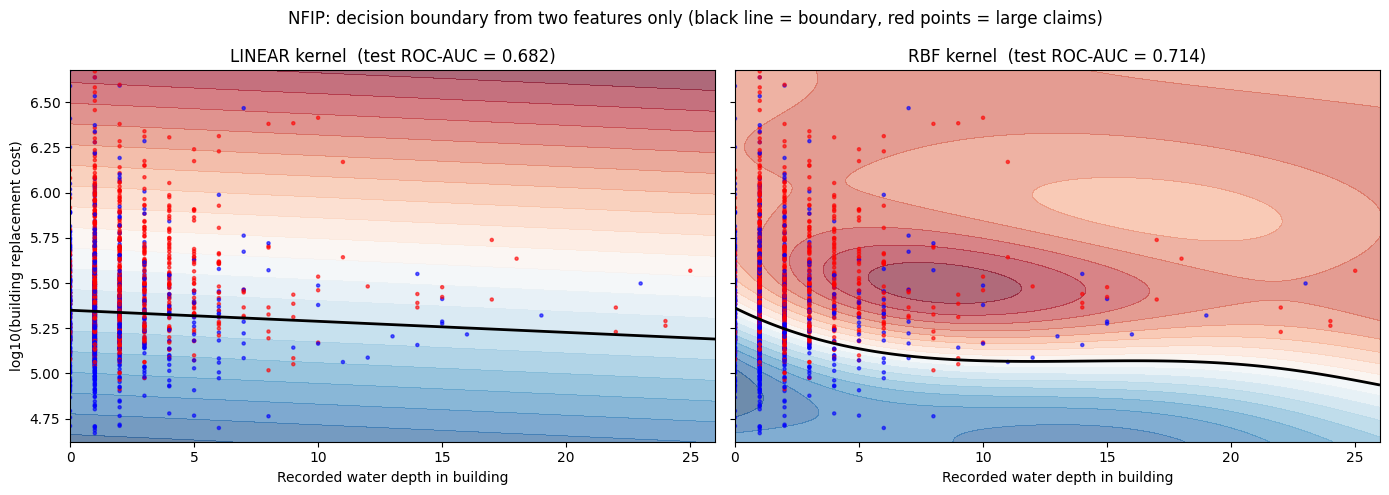

In [6]:
two = ['waterDepth', 'logReplacementCost']
Xa = data[two].values
Xa_train, Xa_test = Xa[train_idx], Xa[test_idx]
ya_train, ya_test = y[train_idx], y[test_idx]
fit_idx, _ = train_test_split(np.arange(len(ya_train)), train_size=5000, stratify=ya_train, random_state=0)

x_lo, x_hi = np.percentile(Xa[:, 0], [1, 99])
y_lo, y_hi = np.percentile(Xa[:, 1], [1, 99])
xx, yy = np.meshgrid(np.linspace(x_lo, x_hi, 300), np.linspace(y_lo, y_hi, 220))
grid_pts = np.c_[xx.ravel(), yy.ravel()]
show = np.random.RandomState(0).choice(len(Xa_test), 2000, replace=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, kernel in zip(axes, ['linear', 'rbf']):
    model = make_pipeline(StandardScaler(), SVC(kernel=kernel, C=1, gamma='scale', class_weight=None))
    model.fit(Xa_train[fit_idx], ya_train[fit_idx])
    auc = roc_auc_score(ya_test, model.decision_function(Xa_test))
    zz = model.decision_function(grid_pts).reshape(xx.shape)
    ax.contourf(xx, yy, zz, levels=20, cmap='RdBu_r', alpha=0.6)
    ax.contour(xx, yy, zz, levels=[0], colors='black', linewidths=2)
    ax.scatter(Xa_test[show, 0], Xa_test[show, 1], c=ya_test[show], cmap='bwr', s=5, alpha=0.6)
    ax.set_xlim(x_lo, x_hi)
    ax.set_ylim(y_lo, y_hi)
    ax.set_title(f'{kernel.upper()} kernel  (test ROC-AUC = {auc:.3f})')
    ax.set_xlabel('Recorded water depth in building')
axes[0].set_ylabel('log10(building replacement cost)')
fig.suptitle('NFIP: decision boundary from two features only (black line = boundary, red points = large claims)')
plt.tight_layout()
plt.show()

### Tuning the kernel, C, and gamma with cross-validation

The three kernels are searched together with 3-fold cross-validation. `C` sets how heavily the SVM is penalized for training points that land on the wrong side of the margin. A small `C` gives a wide, forgiving margin (strong regularization), and a large `C` lets the boundary bend to fit individual points. `gamma` only applies to the RBF kernel and sets how far each support vector's influence reaches. A large `gamma` makes that influence very local, which is the other main way an RBF SVM overfits.

In [7]:
# Linear, polynomial, and RBF kernels searched together on the 8,000-row training sample.
# coef0=1 keeps the lower-order terms in the polynomial kernel instead of only the top-degree ones.
param_grid = [
    {'kernel': ['linear'], 'C': [0.01, 0.1, 1, 10]},
    {'kernel': ['poly'], 'degree': [2, 3], 'coef0': [1], 'C': [0.1, 1, 10]},
    {'kernel': ['rbf'], 'C': [0.1, 1, 10, 100], 'gamma': [0.01, 0.03, 0.1, 0.3, 1, 3, 10]},
]
t0 = time.time()
grid = GridSearchCV(SVC(class_weight=CLASS_WEIGHT, cache_size=1000), param_grid,
                    scoring='roc_auc', cv=CV, n_jobs=-1, return_train_score=True)
grid.fit(X_svm, y_svm, groups=CV_GROUPS)
print(f'Grid search took {time.time() - t0:.0f} seconds')

res = pd.DataFrame(grid.cv_results_)
res['kernel'] = res['param_kernel']
best_by_kernel = (res.sort_values('mean_test_score', ascending=False)
                     .groupby('kernel').head(1)
                     [['kernel', 'params', 'mean_train_score', 'mean_test_score']])
print(best_by_kernel.to_string(index=False))
print()
print('Overall best:', grid.best_params_, ' CV ROC-AUC:', round(grid.best_score_, 4))

Grid search took 46 seconds
kernel                                              params  mean_train_score  mean_test_score
   rbf           {'C': 10, 'gamma': 0.03, 'kernel': 'rbf'}          0.858672         0.838429
  poly {'C': 1, 'coef0': 1, 'degree': 3, 'kernel': 'poly'}          0.857976         0.830596
linear                       {'C': 10, 'kernel': 'linear'}          0.786930         0.784819

Overall best: {'C': 10, 'gamma': 0.03, 'kernel': 'rbf'}  CV ROC-AUC: 0.8384


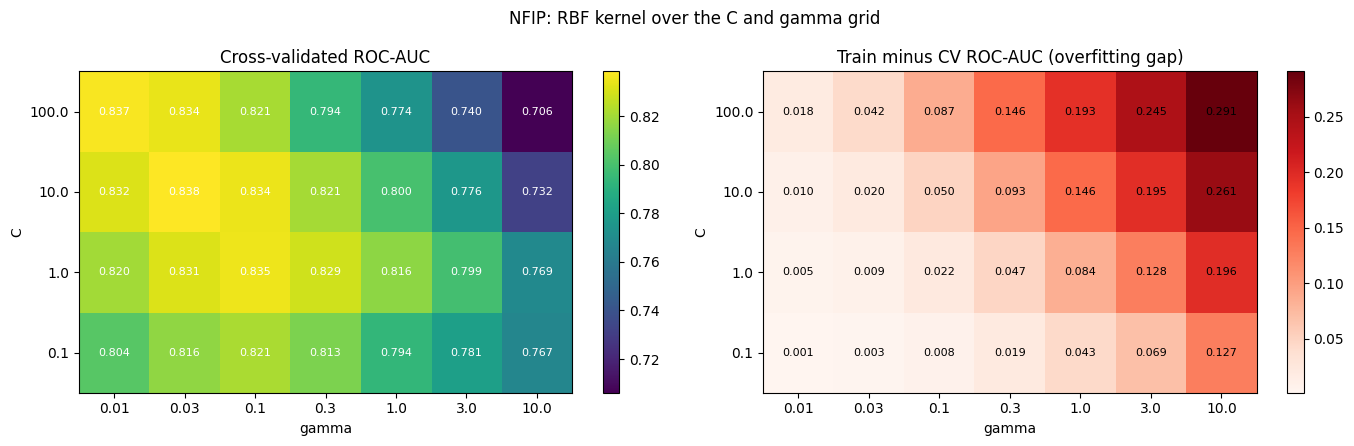

In [8]:
rbf = res[res['kernel'] == 'rbf'].copy()
heat = rbf.pivot_table(index='param_C', columns='param_gamma', values='mean_test_score')
gap = rbf.pivot_table(index='param_C', columns='param_gamma', values='mean_train_score') - heat

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, table, title, cmap in [(axes[0], heat, 'Cross-validated ROC-AUC', 'viridis'),
                               (axes[1], gap, 'Train minus CV ROC-AUC (overfitting gap)', 'Reds')]:
    im = ax.imshow(table.values, cmap=cmap, aspect='auto', origin='lower')
    ax.set_xticks(range(len(table.columns)))
    ax.set_xticklabels(table.columns)
    ax.set_yticks(range(len(table.index)))
    ax.set_yticklabels(table.index)
    ax.set_xlabel('gamma')
    ax.set_ylabel('C')
    ax.set_title(title)
    for i in range(table.shape[0]):
        for j in range(table.shape[1]):
            ax.text(j, i, f'{table.values[i, j]:.3f}', ha='center', va='center', fontsize=8,
                    color='white' if cmap == 'viridis' else 'black')
    fig.colorbar(im, ax=ax)
fig.suptitle(TITLE_PREFIX + ': RBF kernel over the C and gamma grid')
plt.tight_layout()
plt.show()

Validation curve took 9 seconds


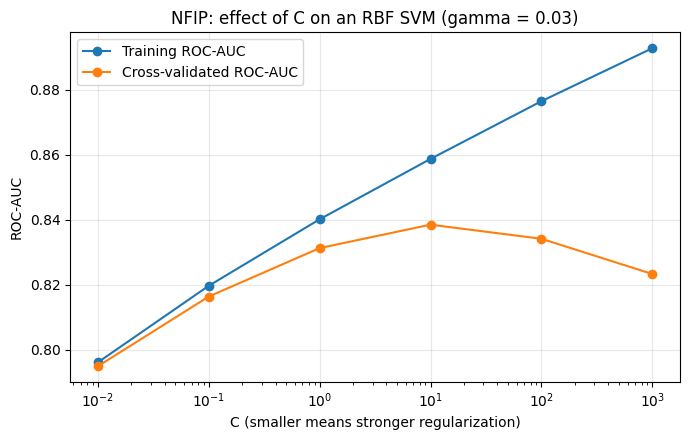

C =    0.01: train 0.796   CV 0.795   gap 0.001
C =     0.1: train 0.820   CV 0.816   gap 0.003
C =       1: train 0.840   CV 0.831   gap 0.009
C =      10: train 0.859   CV 0.838   gap 0.020
C =     100: train 0.876   CV 0.834   gap 0.042
C =    1000: train 0.893   CV 0.823   gap 0.069


In [9]:
best_gamma = grid.best_params_['gamma'] if grid.best_params_['kernel'] == 'rbf' else 0.1
C_range = [0.01, 0.1, 1, 10, 100, 1000]
t0 = time.time()
train_scores, val_scores = validation_curve(
    SVC(kernel='rbf', gamma=best_gamma, class_weight=CLASS_WEIGHT, cache_size=1000),
    X_svm, y_svm, param_name='C', param_range=C_range, groups=CV_GROUPS,
    scoring='roc_auc', cv=CV, n_jobs=-1)
print(f'Validation curve took {time.time() - t0:.0f} seconds')

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.semilogx(C_range, train_scores.mean(axis=1), marker='o', label='Training ROC-AUC')
ax.semilogx(C_range, val_scores.mean(axis=1), marker='o', label='Cross-validated ROC-AUC')
ax.set_xlabel('C (smaller means stronger regularization)')
ax.set_ylabel('ROC-AUC')
ax.set_title(f'{TITLE_PREFIX}: effect of C on an RBF SVM (gamma = {best_gamma})')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

for c, tr, va in zip(C_range, train_scores.mean(axis=1), val_scores.mean(axis=1)):
    print(f'C = {c:>7}: train {tr:.3f}   CV {va:.3f}   gap {tr - va:.3f}')

### Final evaluation on the held-out test set

In [10]:
best_svm = grid.best_estimator_
best_linear_C = best_by_kernel.loc[best_by_kernel['kernel'] == 'linear', 'params'].iloc[0]['C']
linear_svm = SVC(kernel='linear', C=best_linear_C, class_weight=CLASS_WEIGHT, cache_size=1000).fit(X_svm, y_svm)

results = pd.DataFrame([
    evaluate('Majority class', dummy, X_test_s, y_test),
    evaluate('Logistic regression (all training rows)', logreg, X_test_s, y_test),
    evaluate('Linear SVM (tuned C)', linear_svm, X_test_s, y_test),
    evaluate(f"Best SVM ({grid.best_params_['kernel']} kernel)", best_svm, X_test_s, y_test),
])
print('Held-out test set, n =', len(y_test))
print(results.round(3).to_string(index=False))
print()
print('Support vectors in best SVM:', best_svm.n_support_.sum(), 'of', len(y_svm), 'training rows')

Held-out test set, n = 25261
                                  Model  Accuracy  Balanced acc.    F1  ROC-AUC
                         Majority class     0.532          0.500 0.695    0.500
Logistic regression (all training rows)     0.714          0.706 0.759    0.779
                   Linear SVM (tuned C)     0.710          0.701 0.757    0.778
                  Best SVM (rbf kernel)     0.750          0.745 0.778    0.834

Support vectors in best SVM: 4327 of 8000 training rows


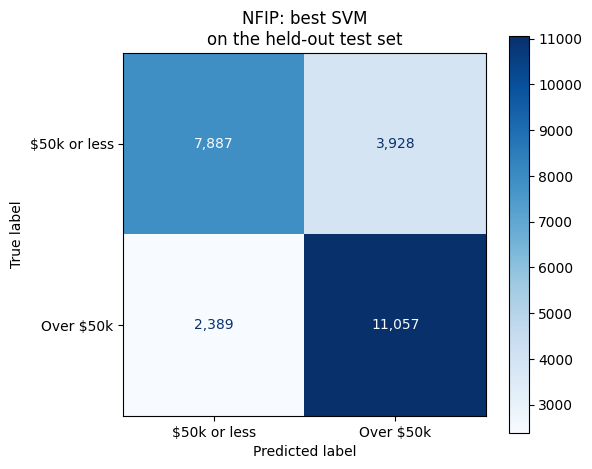

In [11]:
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_estimator(best_svm, X_test_s, y_test, display_labels=CLASS_LABELS,
                                      cmap='Blues', values_format=',', ax=ax)
ax.set_title(f'{TITLE_PREFIX}: best SVM\non the held-out test set')
plt.tight_layout()
plt.show()

In [12]:
# How much does the 8,000-row cap cost? Refit the best settings on smaller and larger samples.
rows = []
for n in [1000, 2000, 4000, 8000, 16000]:
    idx_n, _ = train_test_split(np.arange(len(y_train)), train_size=n, stratify=y_train, random_state=1)
    m = SVC(class_weight=CLASS_WEIGHT, cache_size=1000, **grid.best_params_)
    t0 = time.time()
    m.fit(X_train_s[idx_n], y_train[idx_n])
    rows.append({'Training rows': n, 'Fit seconds': round(time.time() - t0, 1),
                 'Test ROC-AUC': round(roc_auc_score(y_test, m.decision_function(X_test_s)), 4),
                 'Support vectors': m.n_support_.sum()})
print(pd.DataFrame(rows).to_string(index=False))

 Training rows  Fit seconds  Test ROC-AUC  Support vectors
          1000          0.0        0.8140              598
          2000          0.1        0.8291             1159
          4000          0.3        0.8332             2265
          8000          1.4        0.8368             4434
         16000          6.4        0.8389             8734


### Robustness check with location-grouped splitting

Claims from the same neighborhood in the same flood tend to look alike, so a random split can put near-copies of test claims into the training set and make a flexible model look better than it is. The Storm Events notebook turned out to have this exact problem. To see whether it affects the NFIP results, I re-split the data so that every claim from a given latitude and longitude cell lands entirely in train or entirely in test (the public data already rounds coordinates to one decimal place, so each cell is roughly a 10 km square), and refit the three main models.

In [13]:
data['locationCell'] = data['latitude'].round(1).astype(str) + '_' + data['longitude'].round(1).astype(str)
print('Distinct location cells:', data['locationCell'].nunique())

g_train, g_test = next(GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=0)
                       .split(X, y, data['locationCell']))
sc_g = StandardScaler().fit(X[g_train])
Xg_train, Xg_test = sc_g.transform(X[g_train]), sc_g.transform(X[g_test])
yg_train, yg_test = y[g_train], y[g_test]
g_idx, _ = train_test_split(np.arange(len(yg_train)), train_size=8000, stratify=yg_train, random_state=0)

check = {
    'Logistic regression': LogisticRegression(max_iter=2000).fit(Xg_train, yg_train),
    'Linear SVM (tuned C)': SVC(kernel='linear', C=best_linear_C).fit(Xg_train[g_idx], yg_train[g_idx]),
    'Best SVM': SVC(**grid.best_params_).fit(Xg_train[g_idx], yg_train[g_idx]),
}
compare = pd.DataFrame({
    'Random split ROC-AUC': results.set_index('Model')['ROC-AUC'].values[1:],
    'Location-grouped split ROC-AUC': [roc_auc_score(yg_test, m.decision_function(Xg_test)) for m in check.values()],
}, index=check.keys()).round(3)
compare

Distinct location cells: 3580


,Random split ROC-AUC,Location-grouped split ROC-AUC
Logistic regression,0.779,0.783
Linear SVM (tuned C),0.778,0.779
Best SVM,0.834,0.831


### Overfitting

Three things kept the SVMs from overfitting. The first is the regularization parameter `C`, which was tuned by cross-validation instead of left at its default. The validation curve shows what it does. At `C = 0.01` the training and cross-validated ROC-AUC are almost identical (0.796 and 0.795), but the model is too stiff to follow the depth pattern. As `C` grows the training score keeps climbing, while the cross-validated score peaks at `C = 10` (0.838) and then falls to 0.823 at `C = 1000`, with the gap between the two widening from 0.001 to 0.069. That turning point is where the model starts fitting noise.

The second is `gamma`. The right-hand heatmap shows the train minus CV gap across the whole grid, and it grows much faster along the `gamma` axis than along the `C` axis. At `C = 100` and `gamma = 10` the gap reaches 0.291 and the cross-validated score drops to 0.706, worse than the logistic regression baseline. A large `gamma` lets each support vector draw a small island around itself, so the model ends up memorizing individual training claims.

The third is checking the final model on data it never touched, in two ways. The held-out test set of 25,261 claims gives an ROC-AUC of 0.834, close to the 0.838 from cross-validation, so the tuning did not overfit the validation folds. The location-grouped check gives 0.831, so the model is not leaning on near-copies of test claims from the same neighborhoods.

### Metrics and hyperparameter tuning

ROC-AUC was the tuning metric because it scores how well the model ranks large claims above small ones across every possible cutoff, rather than at one threshold. The test results also include accuracy, balanced accuracy, and F1, which are easier to read as a real decision. The classes are close to balanced (53% large), so accuracy is meaningful here, and always guessing the majority class scores 0.532.

The grid covered a linear kernel with `C` from 0.01 to 10, a polynomial kernel of degree 2 or 3, and an RBF kernel with `C` from 0.1 to 100 and `gamma` from 0.01 to 10, all with 3-fold cross-validation on the 8,000-row sample. The RBF kernel won at `C = 10` and `gamma = 0.03` (CV ROC-AUC 0.838), ahead of the cubic polynomial (0.831) and the linear kernel (0.785). In plain terms, `C = 10` means the model is willing to bend the boundary a fair amount to get individual claims right, and `gamma = 0.03` on standardized features means each support vector's influence reaches across a wide region, which keeps the boundary smooth. The heatmap also shows a diagonal ridge where a higher `C` paired with a lower `gamma` scores about the same (0.837 at `C = 100` with `gamma = 0.01`, and 0.835 at `C = 1` with `gamma = 0.1`). The two settings trade off against each other, so staying on that ridge matters more than the exact winner.

On the test set the tuned RBF SVM reached 0.750 accuracy, 0.745 balanced accuracy, 0.778 F1, and 0.834 ROC-AUC. The confusion matrix shows its mistakes lean one way. It finds 11,057 of the 13,446 large claims (82%), but it also flags 3,928 of the 11,815 smaller claims as large, so it is better at catching expensive claims than at clearing cheap ones.

### The 8,000-row sample

Kernel SVM training time grows roughly with the square of the number of rows, which is why the SVMs were fit on a sample. The size check shows the sample costs very little. Going from 8,000 to 16,000 rows raised test ROC-AUC from 0.837 to 0.839 while fit time went from 1.4 to 6.4 seconds, and most of the gain happens early, between 1,000 rows (0.814) and 4,000 rows (0.833). In the tuned model, 4,327 of the 8,000 training claims end up as support vectors. More than half the data sitting on or inside the margin means the two classes overlap heavily, and many claims land close to the boundary wherever it is drawn.

### Expected or unexpected

I expected the RBF kernel to beat the linear one, since the depth table showed a relationship that rises and then flattens. What I did not expect was how little the linear SVM added over logistic regression. The two scored 0.778 and 0.779 ROC-AUC, even though logistic regression saw about nine times as much data. When the boundary has to be a straight line, the choice of loss function hardly matters and the extra rows do not help much either. The whole gain came from the kernel, which lifted ROC-AUC by about 0.056.

The two-feature plot shows where that gain comes from. The linear boundary on water depth and replacement cost is nearly flat and scores 0.682. The RBF boundary drops steeply over the first few units of depth and then levels out, tracking the same shape as the depth table, and scores 0.714. It also carves out a pocket of large claims at moderate depth and mid-range replacement cost that no straight line could represent.

The surprise on the data side was the water depth variable itself. Every value is a whole number, the median is 1, and the median payout nearly doubles between a recorded depth of 1 and a depth of 3 ($48,285 to $91,133). Two units of water producing that much extra damage reads much more like feet than inches, so I labeled it as recorded depth without a unit. The SVM only sees scaled values, so the model is unaffected, but the units need confirming before anyone reads a depth threshold off these results. The 99 claims above 100 and the negative values (down to -36) also look like entry errors, or like depth measured from a different reference point.

### How EDA helped

The EDA shaped this notebook in three places. The Module B work and the Week 2 notebook showed that damage amount predicts payout almost perfectly, which is why every damage and payout field was left out here, since including one would turn the task back into a lookup. Replacement cost and coverage span several orders of magnitude, which is why both are log-scaled, because otherwise an RBF kernel would measure distance almost entirely along those two columns. And the depth table predicted that a curved boundary would beat a straight one before any SVM was fit, which the kernel comparison then confirmed.

The one place I expected EDA to point to a problem and it did not was location. Hurricane Harvey accounts for most 2017 claims, and I worried the model would lean on where claims came from. The location-grouped check shows it holds up when whole neighborhoods are held out, so it is learning something about the buildings and the water rather than memorizing specific places.

### External sources

- scikit-learn User Guide, "1.4. Support Vector Machines": https://scikit-learn.org/stable/modules/svm.html
- scikit-learn example, "RBF SVM parameters," which uses the same kind of C and gamma heatmap and shows the diagonal tradeoff between them: https://scikit-learn.org/stable/auto_examples/svm/plot_rbf_parameters.html
- Hsu, Chang, and Lin, "A Practical Guide to Support Vector Classification" (the LIBSVM guide), which recommends scaling features, starting with the RBF kernel, and searching C and gamma on an exponential grid: https://www.csie.ntu.edu.tw/~cjlin/papers/guide/guide.pdf
- James, Witten, Hastie, and Tibshirani, *An Introduction to Statistical Learning*, Chapter 9 ("Support Vector Machines").

### Conclusions

Using only building, policy, and flood characteristics, with no damage or payout fields, a tuned RBF SVM separates claims over $50,000 from smaller ones with a test ROC-AUC of 0.834 and 75% accuracy, compared with 0.779 for logistic regression and 53% for always guessing the majority class. The improvement comes from the kernel, because a straight boundary cannot follow the way claim size rises with water depth and then levels off. Regularization mattered in both directions. A `C` that was too small left the model underfit, a large `gamma` pushed it into memorizing individual claims, and cross-validation found a setting that held up on both a random and a location-grouped test set.

For the Capstone this is encouraging, since it suggests claim severity can be predicted reasonably well without looking at the claim's own dollar amounts. The weak point is that the strongest single feature, water depth, is recorded after the flood and has unclear units. The next step is to see how much of this signal survives when depth is replaced with something known in advance, such as elevation relative to the base flood elevation or land cover around the building.